# Exploratory Data Analysis on Superstore Retail Sales

## 1. Project Overview

### Project Objective

The objective of this project is to explore the Superstore Retail Sales dataset to understand customer purchasing behaviour, sales trends, product category performance, discount sensitivity, regional performance and customer segment profitability.

The analysis will be carried out using Python, Pandas, Matplotlib and Seaborn.

### Key Areas of Analysis

- Monthly sales trends and seasonality.
- Customer purchasing behaviour and revenue contribution.
- Product category and sub-category performance.
- Relationship between discounts and profit.
- Regional sales and profitability.
- Customer segment performance.

### Dataset

The dataset contains retail transaction records, including order dates, customer information, product categories, sales, quantities, discounts and profits.

## 2. Importing Libraries and Loading the Dataset

The libraries required for this analysis are imported below.

- **Pandas:** Data manipulation and analysis.
- **NumPy:** Numerical operations.
- **Matplotlib:** Data visualisation.
- **Seaborn:** Statistical data visualisation.

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

In [72]:
# Loading the dataset
df = pd.read_csv("superstore_sales.csv")

## 3. Data Inspection and Understanding

The dataset is inspected to understand its structure, dimensions, column names, data types and general characteristics before carrying out data cleaning and analysis.

In [73]:
# Displaying the first five rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [74]:
# Displaying the last five rows
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
# Displaying the number of rows and columns
df.shape

(10800, 21)

In [76]:
# Displaying all colum names
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [77]:
# Checking data types and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [78]:
# Descriptive statistics of numerical columns
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 4. Data Cleaning and Preparation

### 4.1 Missing Value Analysis

The dataset is examined for missing values to identify columns with incomplete records. Both the number and percentage of missing values are calculated.

In [79]:
# Checking the number of missing Values
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

In [80]:
# Calculating the percentage of missing values
(df.isnull().sum() / len(df)) * 100

Row ID           0.000000
Order ID         0.000000
Order Date       7.462963
Ship Date        7.462963
Ship Mode        7.462963
Customer ID      7.462963
Customer Name    7.462963
Segment          7.462963
Country          7.462963
City             7.462963
State            7.462963
Postal Code      7.564815
Region           7.462963
Product ID       7.462963
Category         7.462963
Sub-Category     7.462963
Product Name     7.462963
Sales            7.462963
Quantity         7.462963
Discount         7.462963
Profit           7.462963
dtype: float64

### 4.2 Identifying Duplicate Records and Supplementary Tables

The dataset contains 10,800 rows. However, initial inspection reveals that the sales transaction records are followed by supplementary tables containing manager and returned-order information.

These supplementary tables do not share the same structure as the sales transaction records. Therefore, they need to be excluded before carrying out the sales analysis.

The rows around the transition point are inspected to identify where the sales records end and the supplementary tables begin.

In [81]:
# Checking the last few rows of the dataset
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [82]:
# Inspecting rows around the transition between sales and supplementary tables
df.iloc[9990:10005]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9990,9991,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2.0,0.0,15.6332
9991,9992,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2.0,0.2,19.3932
9992,9993,CA-2018-121258,2/26/2018,3/3/2018,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627.0,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4.0,0.0,13.3200
9993,9994,CA-2018-119914,5/4/2018,5/9/2018,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683.0,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2.0,0.0,72.9480
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [83]:
# Checking for duplicates within the sales transaction records
df.iloc[:9994].duplicated().sum()

np.int64(0)

The inspection shows that the sales transaction records end at index 9993. A manager table begins at index 9994, followed by a returned-orders table.

The supplementary tables are excluded so that the analysis focuses only on the 9,994 sales transactions.

No duplicate records were identified within the isolated sales transaction records.

In [84]:
# Selecting only the sales transaction records
sales = df.iloc[:9994].copy()

In [85]:
# Checking the dimensions of the cleaned sales dataset
sales.shape

(9994, 21)

### 4.3 Missing Values in the Sales Dataset

After isolating the sales records, missing values are examined again.

The missing values are found only in the Postal Code column. Since Postal Code is not required for the planned sales, profit, customer or discount analyses, the affected records are retained rather than deleted or assigned invented postal codes.

In [86]:
# Checking missing values in the sales dataset
sales.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [87]:
# Calculating the percentage of missing values
(sales.isnull().sum() / len(sales)) * 100

Row ID           0.000000
Order ID         0.000000
Order Date       0.000000
Ship Date        0.000000
Ship Mode        0.000000
Customer ID      0.000000
Customer Name    0.000000
Segment          0.000000
Country          0.000000
City             0.000000
State            0.000000
Postal Code      0.110066
Region           0.000000
Product ID       0.000000
Category         0.000000
Sub-Category     0.000000
Product Name     0.000000
Sales            0.000000
Quantity         0.000000
Discount         0.000000
Profit           0.000000
dtype: float64

There are 11 missing values in the Postal Code column, representing approximately 0.11% of the sales records.

These records are retained because the missing postal codes do not prevent the planned analysis.

The Order Date and Ship Date columns are initially stored as strings. They are converted to datetime format to allow date-based operations and time-series analysis.

In [88]:
# Checking the initial data types
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   str    
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [89]:
# Converting date columns to datetime format
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Ship Date"] = pd.to_datetime(sales["Ship Date"])

In [90]:
# Confirming the updated data types
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   str           
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [91]:
# Displaying the converted date columns
sales[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


## 5. Feature Engineering

Feature engineering is carried out to extract useful information from the existing date columns.

The year, month number and month name are extracted from the Order Date column. These features will be used to analyse monthly sales patterns and compare sales performance across different years.

In [92]:
# Extracting the order year
sales["Order Year"] = sales["Order Date"].dt.year

# Extracting the order month number
sales["Order Month"] = sales["Order Date"].dt.month

# Extracting the order month name
sales["Order Month Name"] = sales["Order Date"].dt.month_name()

In [93]:
# Displaying the newly created date features
sales[["Order Date", "Order Year", "Order Month", "Order Month Name"]].head()

,Order Date,Order Year,Order Month,Order Month Name
0,2017-11-08,2017,11,November
1,2017-11-08,2017,11,November
2,2017-06-12,2017,6,June
3,2016-10-11,2016,10,October
4,2016-10-11,2016,10,October


## 6. Exploratory Data Analysis

This section explores the sales dataset to identify patterns and relationships across different business areas.

### 6.1 Monthly Sales Trends

Monthly sales are analysed to identify the months with the highest and lowest sales.

The total sales for each calendar month are calculated across all years in the dataset. This provides an overview of the general monthly sales distribution.

In [109]:
# Grouping sales by months
monthly_sales = sales.groupby("Order Month").agg(
    Total_Sales = ("Sales", "sum")
)

# Adding month names
monthly_sales["Month Name"] = monthly_sales.index.map(lambda month: calendar.month_name[month])

monthly_sales


,Total_Sales,Month Name
Order Month,,
1,94924.8356,January
2,59751.2514,February
3,205005.4888,March
4,137762.1286,April
5,155028.8117,May
6,152718.6793,June
7,147238.0970,July
8,159044.0630,August
9,307649.9457,September


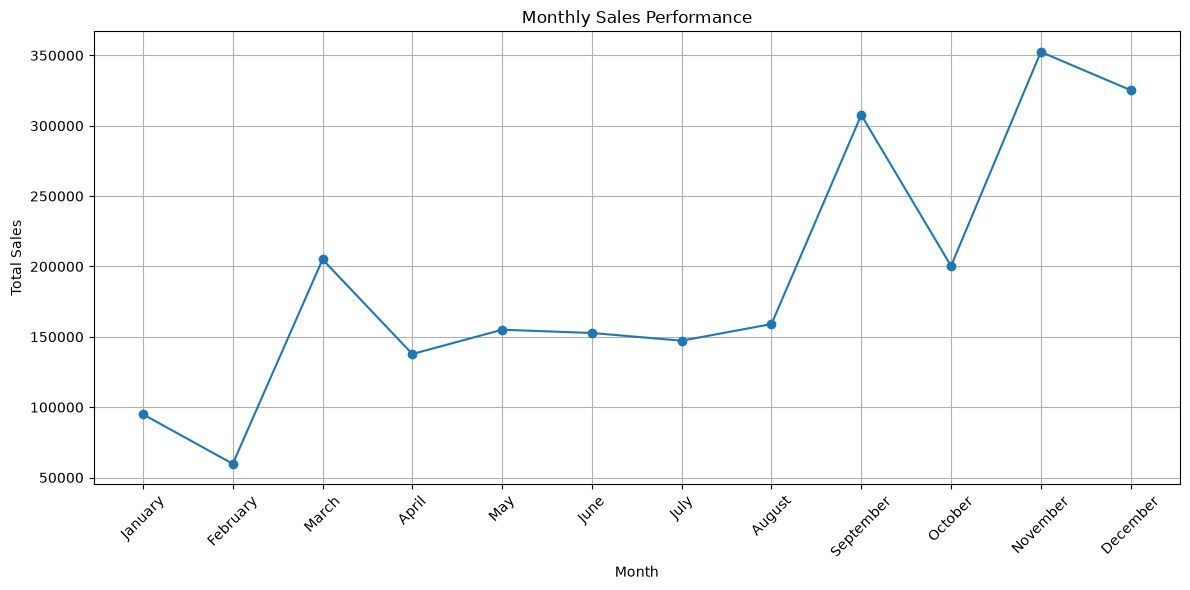

In [110]:
# Visualising monthly sales performance
plt.figure(figsize=(12, 6))
plt.plot(monthly_sales["Month Name"], monthly_sales["Total_Sales"], marker="o")
plt.title("Monthly Sales Performance")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

The monthly sales analysis shows differences in sales performance across the months. November records the highest total sales, while February records the lowest.

The higher sales observed towards the end of the year may be associated with increased seasonal or festive-period purchasing. However, the dataset alone does not establish the cause of this pattern.

In [111]:
# Grouping Sales by Year and Month
yearly_monthly_sales = sales.pivot_table(index="Order Month",
                                         columns="Order Year",
                                         values="Sales",
                                         aggfunc="sum")
yearly_monthly_sales

Order Year,2015,2016,2017,2018
Order Month,,,,
1,14236.8950,18174.0756,18542.4910,43971.3740
2,4519.8920,11951.4110,22978.8150,20301.1334
3,55691.0090,38726.2520,51715.8750,58872.3528
4,28295.3450,34195.2085,38750.0390,36521.5361
5,23648.2870,30131.6865,56987.7280,44261.1102
6,34595.1276,24797.2920,40344.5340,52981.7257
7,33946.3930,28765.3250,39261.9630,45264.4160
8,27909.4685,36898.3322,31115.3743,63120.8880
9,81777.3508,64595.9180,73410.0249,87866.6520


In [112]:
# Comparing November sales across the different years
yearly_monthly_sales.loc[11]

Order Year
2015     78628.7167
2016     75972.5635
2017     79411.9658
2018    118447.8250
Name: 11, dtype: float64

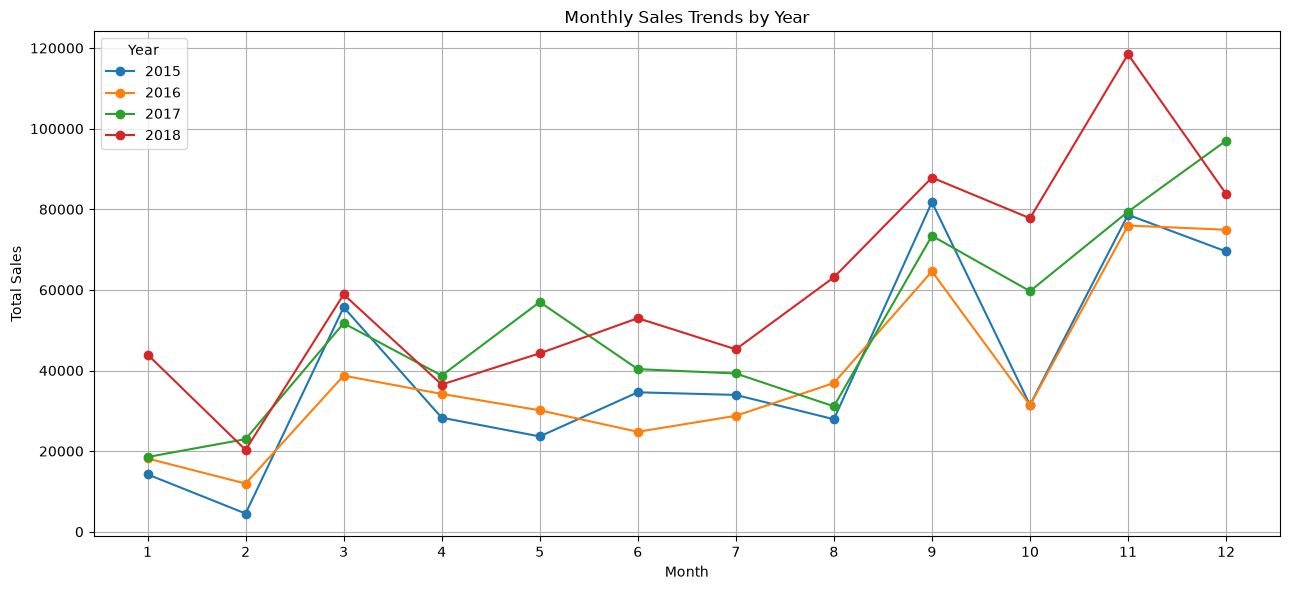

In [113]:
# Visualising monthly sales trends by year
plt.figure(figsize=(13, 6))
for year in yearly_monthly_sales.columns:
    plt.plot(
        yearly_monthly_sales.index, yearly_monthly_sales[year], marker="o", label=year
    )
plt.title("Monthly Sales Trends by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(True)
plt.tight_layout()
plt.show()

The yearly comparison shows how monthly sales change from one year to another.

The results can be used to identify months with consistently strong or weak sales and to examine whether the overall monthly pattern is similar across the four years.

### 6.2 Customer Purchasing Behaviour

This section examines customer purchasing behaviour using order frequency, total sales per customer and average order value.

The analysis helps distinguish customers who place orders frequently from customers who generate higher sales revenue.

In [114]:
# Number of unique customers
print(sales["Customer ID"].nunique())

793


In [115]:
# Calculating the number of unique orders per customer
customer_orders = sales.groupby("Customer ID")["Order ID"].nunique()

# Top 10 customers by order frequency
top_customers = customer_orders.sort_values(ascending=False).head(10)
top_customers

Customer ID
EP-13915    17
SH-19975    13
NS-18640    13
PG-18820    13
ZC-21910    13
EA-14035    13
JE-15745    13
CK-12205    13
AH-10690    12
RB-19465    12
Name: Order ID, dtype: int64

The number of unique orders is used instead of counting transaction rows because a single order may contain multiple product line items.

This provides a more accurate measure of how frequently each customer places orders.

In [116]:
# Calculating total sales per customer
customer_sales = sales.groupby("Customer ID")["Sales"].sum()

# Top 10 customers by total sales
top_revenue_customers = customer_sales.sort_values(ascending=False).head(10)
top_revenue_customers

Customer ID
SM-20320    25043.050
TC-20980    19052.218
RB-19360    15117.339
TA-21385    14595.620
AB-10105    14473.571
KL-16645    14175.229
SC-20095    14142.334
HL-15040    12873.298
SE-20110    12209.438
CC-12370    12129.072
Name: Sales, dtype: float64

Customer value is examined using total orders, total sales and average order value.

Average Order Value is calculated by dividing the total sales generated by a customer by the number of unique orders placed by that customer.

In [117]:
# Combining customer orders and sales into one DataFrame
customer_analysis = pd.DataFrame({
    "Total Orders": customer_orders,
    "Total Sales": customer_sales
})

# Calculating average order value
customer_analysis["Average Order Value"] = customer_analysis["Total Sales"]/customer_analysis["Total Orders"]
customer_analysis.head()

,Total Orders,Total Sales,Average Order Value
Customer ID,,,
AA-10315,5,5563.560,1112.712000
AA-10375,9,1056.390,117.376667
AA-10480,4,1790.512,447.628000
AA-10645,6,5086.935,847.822500
AB-10015,3,886.156,295.385333


In [118]:
# Top 5 customers by average order value
top_aov_customers = customer_analysis.sort_values(by="Average Order Value", ascending=False).head(5)
top_aov_customers

,Total Orders,Total Sales,Average Order Value
Customer ID,,,
SM-20320,5,25043.050,5008.610000
TC-20980,5,19052.218,3810.443600
TA-21385,4,14595.620,3648.905000
GT-14635,3,9351.212,3117.070667
BM-11140,4,11789.630,2947.407500


In [119]:
# Top 5 customers by total sales
top_sales_customer = customer_analysis.sort_values(by="Total Sales", ascending=False).head(5)
top_sales_customer

,Total Orders,Total Sales,Average Order Value
Customer ID,,,
SM-20320,5,25043.050,5008.6100
TC-20980,5,19052.218,3810.4436
RB-19360,6,15117.339,2519.5565
TA-21385,4,14595.620,3648.9050
AB-10105,10,14473.571,1447.3571


The distribution of total sales per customer is examined to understand how revenue is spread across the customer base.

In [120]:
# Descriptive statistics of customer sales
customer_analysis["Total Sales"].describe()

count      793.000000
mean      2896.848500
std       2628.670117
min          4.833000
25%       1146.050000
50%       2256.394000
75%       3785.276000
max      25043.050000
Name: Total Sales, dtype: float64

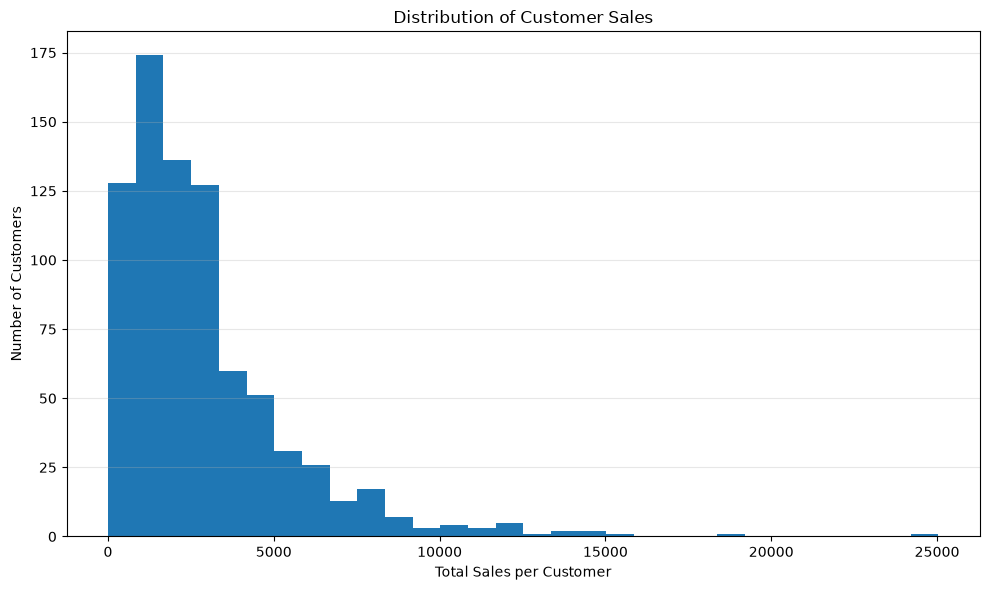

In [126]:
# Visualising the distribution of customer sales
plt.figure(figsize=(10,6))
plt.hist(customer_analysis["Total Sales"], bins=30)
plt.title("Distribution of Customer Sales")
plt.xlabel("Total Sales per Customer")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The histogram shows that customer sales are concentrated towards the lower end, with a smaller number of customers generating considerably higher sales.

This indicates a right-skewed distribution of customer revenue. The mean and median can also be compared to understand the extent of this skewness.

### 6.3 Product Category and Sub-category Performance

This section examines the financial performance of product categories and sub-categories using total sales, total profit and profit margin.

Profit margin is calculated as:

Profit Margin (%) = (Total Profit / Total Sales) × 100

This measures the proportion of sales revenue retained as profit.

In [127]:
# Analysing performance by product category
category_analysis = sales.groupby("Category").agg({"Sales":"sum","Profit":"sum"})

# Calculating profit margin
category_analysis["Profit Margin (%)"] = (category_analysis["Profit"] / category_analysis["Sales"])*100
category_analysis

,Sales,Profit,Profit Margin (%)
Category,,,
Furniture,741999.7953,18451.2728,2.486695
Office Supplies,719047.0320,122490.8008,17.035158
Technology,836154.0330,145454.9481,17.395712


### Sub-category Performance

The analysis is further broken down into product sub-categories to identify which products contribute most to sales and profit, as well as those generating losses.

In [128]:
# Analysing performance by product sub-category
subcategory_analysis = sales.groupby("Sub-Category").agg({"Sales":"sum", "Profit":"sum"})

# Calculating profit margin
subcategory_analysis["Profit Margin (%)"] = (subcategory_analysis["Profit"] / subcategory_analysis["Sales"])*100

# Sorting sub-categories by total profit
subcategory_analysis.sort_values(by="Profit", ascending=True)

,Sales,Profit,Profit Margin (%)
Sub-Category,,,
Tables,206965.5320,-17725.4811,-8.564460
Bookcases,114879.9963,-3472.5560,-3.022768
Supplies,46673.5380,-1189.0995,-2.547695
Fasteners,3024.2800,949.5182,31.396504
Machines,189238.6310,3384.7569,1.788618
Labels,12486.3120,5546.2540,44.418672
Art,27118.7920,6527.7870,24.071083
Envelopes,16476.4020,6964.1767,42.267582
Furnishings,91705.1640,13059.1436,14.240358


In [129]:
# Identifying loss-making sub-categories
loss_making_subcategories = subcategory_analysis[subcategory_analysis["Profit"] < 0]
loss_making_subcategories

,Sales,Profit,Profit Margin (%)
Sub-Category,,,
Bookcases,114879.9963,-3472.5560,-3.022768
Supplies,46673.5380,-1189.0995,-2.547695
Tables,206965.5320,-17725.4811,-8.564460


The analysis identifies three loss-making sub-categories: Bookcases, Supplies and Tables.

Tables records the largest total loss among these sub-categories. This makes it an important area for further investigation.

### 6.4 Discount Sensitivity Analysis

This section investigates the relationship between discounts and profitability.

The analysis examines total sales, total profit and quantity sold at different discount levels. A scatter plot and correlation coefficient are also used to explore the relationship between discount and profit.

In [ ]:
# Grouping sales by discount level
discount_analysis = sales.groupby("Discount").agg(
    Total_Sales=("Sales","sum"),
    Total_Profit=("Profit","sum"),
    Total_Quantity=("Quantity", "sum")
)

# Calculating profit margin
discount_analysis["Profit Margin (%)"] = (discount_analysis["Total_Profit"]/discount_analysis["Total_Sales"])*100
discount_analysis

,Total_Sales,Total_Profit,Total_Quantity,Profit Margin (%)
Discount,,,,
0.00,1.087908e+06,320987.6032,18267.0,29.505019
0.10,5.436935e+04,9029.1770,373.0,16.607108
0.15,2.755852e+04,1418.9915,198.0,5.149012
0.20,7.645944e+05,90337.3060,13660.0,11.815063
0.30,1.032267e+05,-10369.2774,849.0,-10.045155
0.32,1.449346e+04,-2391.1377,105.0,-16.498047
0.40,1.164178e+05,-23057.0504,786.0,-19.805437
0.45,5.484974e+03,-2493.1111,45.0,-45.453472
0.50,5.891854e+04,-20506.4281,241.0,-34.804712


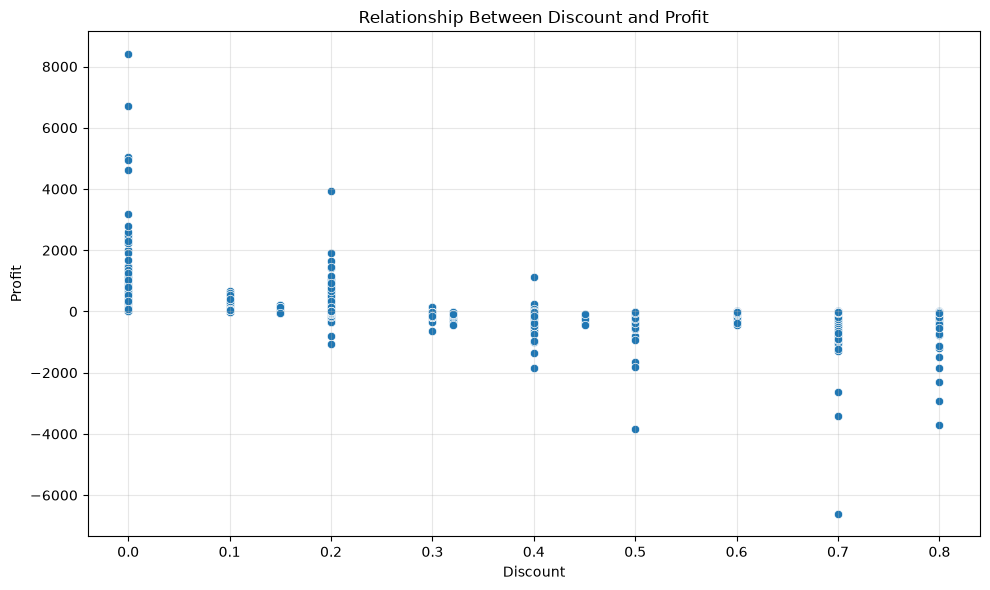

In [134]:
# Visualising the relationship between discount and profit
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sales, x="Discount", y="Profit")
plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [135]:
# Calculating the overall correlation between discount and profit
correlation = sales["Discount"].corr(sales["Profit"])
print("Correlation between Discount and Profit:", correlation)

Correlation between Discount and Profit: -0.21948745637176834


The overall correlation coefficient indicates a negative relationship between discount and profit.

However, correlation does not establish causation.

The scatter plot is useful for examining the spread of individual transaction profits across discount levels.

In [136]:
# Calculating the correlation between discount and profit by category
category_discount_correlation = sales.groupby("Category").apply(lambda group: group["Discount"].corr(group["Profit"]))
category_discount_correlation

Category
Furniture         -0.483769
Office Supplies   -0.208787
Technology        -0.268853
dtype: float64

In [137]:
# Selecting Furniture transactions
furniture = sales[sales["Category"]=="Furniture"]

# Calculating discount-profit correlation by Furniture sub-category
furniture_discount_correlation = furniture.groupby("Sub-Category").apply(lambda group: group["Discount"].corr(group["Profit"]))
furniture_discount_correlation

Sub-Category
Bookcases     -0.607067
Chairs        -0.591815
Furnishings   -0.471598
Tables        -0.671770
dtype: float64

The Furniture sub-category analysis shows that discount and profit are negatively associated across its sub-categories.

Tables is examined further because it records the largest total loss among the loss-making sub-categories.

In [138]:
# Selecting Tables transactions
furniture_tables = sales[sales["Sub-Category"]=="Tables"]

# Calculating average profit at each discount level
table_discount_profits = furniture_tables.groupby("Discount")["Profit"].mean()
table_discount_profits

Discount
0.00    184.393051
0.20     -4.275465
0.30    -63.006067
0.40   -215.831957
0.45   -226.646464
0.50   -239.316314
Name: Profit, dtype: float64

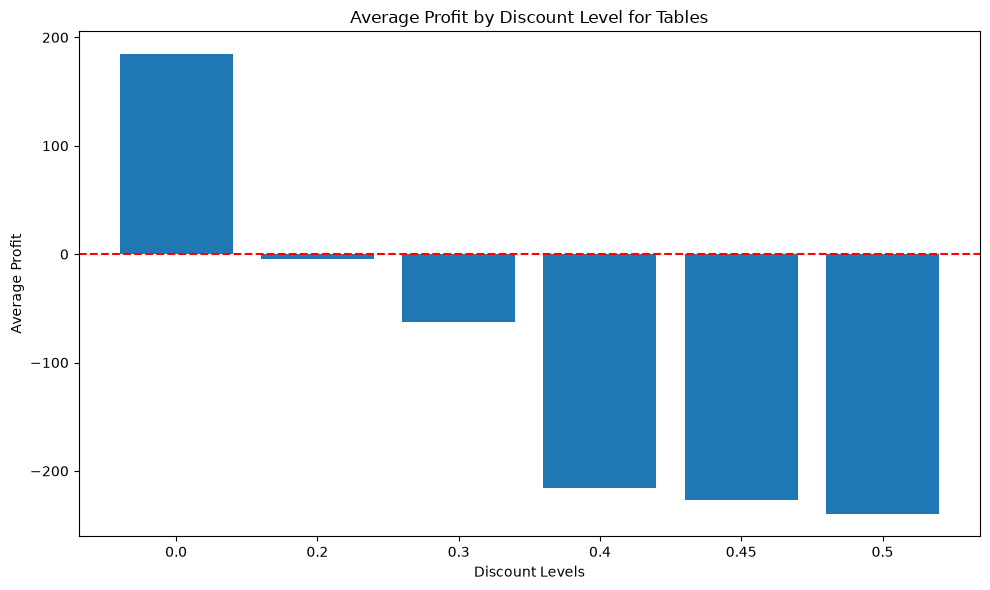

In [139]:
# Visualising average profit by discount level for Tables
plt.figure(figsize=(10, 6))
plt.bar(table_discount_profits.index.astype(str), table_discount_profits.values)
plt.title("Average Profit by Discount Level for Tables")
plt.xlabel("Discount Levels")
plt.ylabel("Average Profit")
plt.axhline(0, color="red", linestyle="--")
plt.tight_layout()
plt.show()

The analysis of Tables shows that average profit decreases as the discount level increases.

Transactions with no discount generate positive average profit, while the average profit becomes negative at the 20% discount level and declines further at higher discount levels.

This suggests that the discount strategy for Tables should be reviewed, particularly at higher discount levels.

However, the analysis shows an association rather than proving that discounts alone cause the losses.

### 6.5 Regional Performance Analysis

This section compares sales and profitability across the four regions.

Total sales, total profit and profit margin are calculated to identify the strongest and weakest regional performances.

In [140]:
# Grouping sales and profit by region
regional_analysis = sales.groupby("Region").agg(
    Total_Sales = ("Sales", "sum"),
    Total_Profit = ("Profit", "sum")
)

# Calculating profit margin
regional_analysis["Profit Margin (%)"] = (regional_analysis["Total_Profit"]/regional_analysis["Total_Sales"])*100
regional_analysis

,Total_Sales,Total_Profit,Profit Margin (%)
Region,,,
Central,501239.8908,39706.3625,7.921629
East,678781.2400,91522.7800,13.483399
South,391721.9050,46749.4303,11.934342
West,725457.8245,108418.4489,14.944831


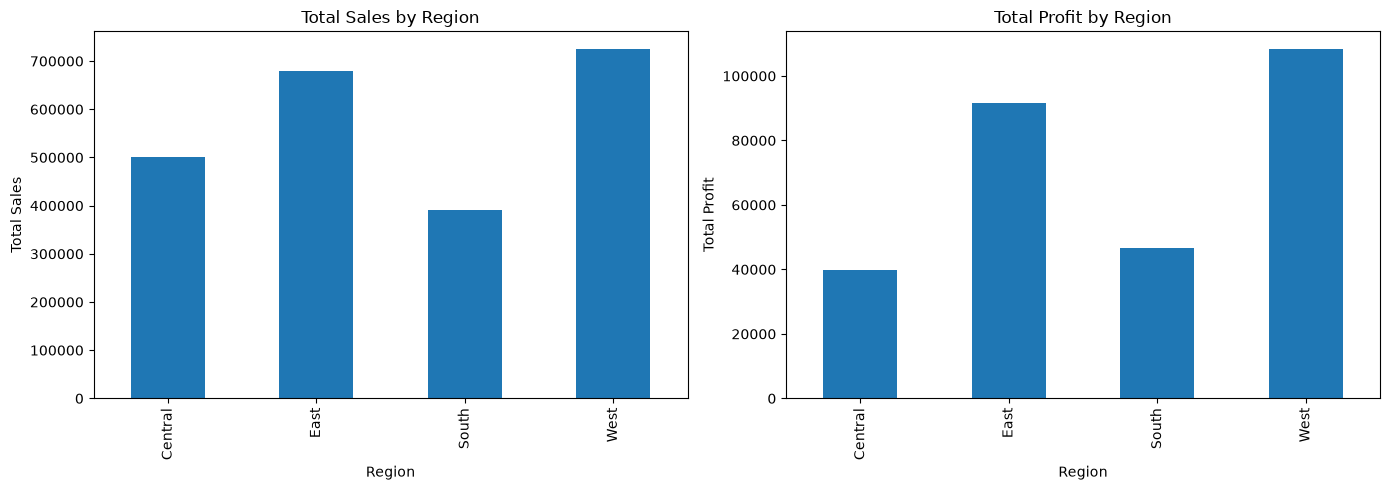

In [141]:
# Comparing regional sales and profit using separate charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
regional_analysis["Total_Sales"].plot(
    kind="bar", ax=axes[0], title="Total Sales by Region"
)
regional_analysis["Total_Profit"].plot(
    kind="bar", ax=axes[1], title="Total Profit by Region"
)
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Total Sales")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Total Profit")
plt.tight_layout()
plt.show()

The regional analysis highlights differences in sales and profitability across the four regions.

Comparing total sales, total profit and profit margin provides a more complete picture of regional performance than relying on sales revenue alone.

### 6.6 Customer Segment Analysis

The final analysis compares the performance of the Consumer, Corporate and Home Office customer segments.

Total sales, total profit and profit margin are used to assess the financial contribution of each segment.

In [142]:
# Grouping sales and profit by customer segment
segment_analysis = sales.groupby("Segment").agg(
    Total_Sales = ("Sales", "sum"),
    Total_Profit = ("Profit", "sum")
)

# Calculating profit margin
segment_analysis["Profit Margin (%)"] = (segment_analysis["Total_Profit"]/segment_analysis["Total_Sales"])*100
segment_analysis

,Total_Sales,Total_Profit,Profit Margin (%)
Segment,,,
Consumer,1.161401e+06,134119.2092,11.548050
Corporate,7.061464e+05,91979.1340,13.025506
Home Office,4.296531e+05,60298.6785,14.034269


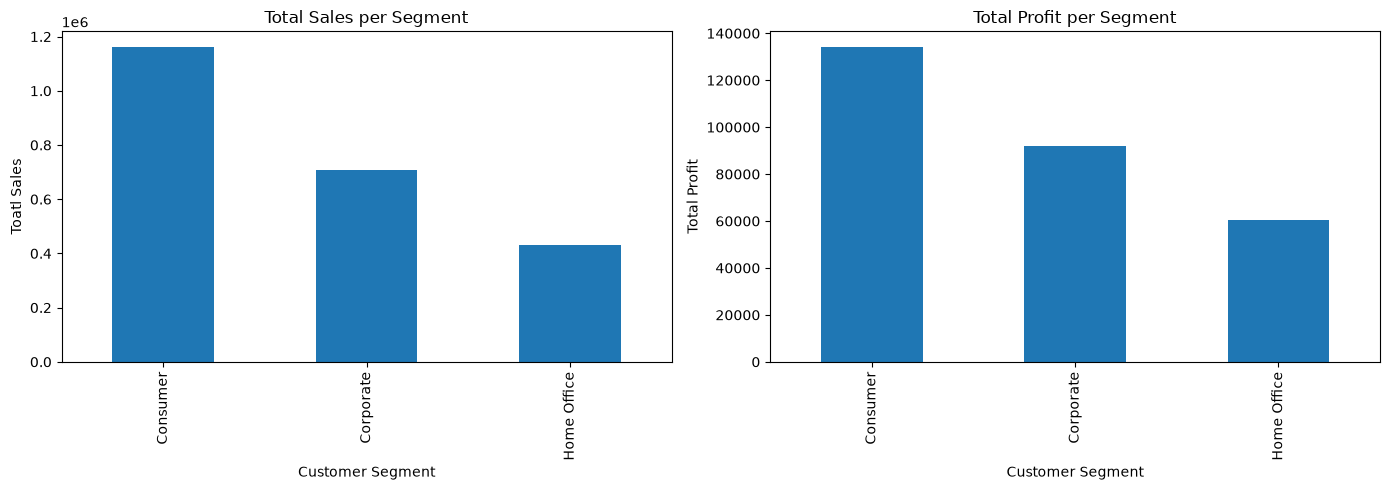

In [144]:
# Comparing sales and profit across customer segments
fig, axes = plt.subplots(1, 2, figsize=(14,5))

segment_analysis["Total_Sales"].plot(kind="bar", ax=axes[0], title="Total Sales per Segment")
segment_analysis["Total_Profit"].plot(kind="bar", ax=axes[1], title="Total Profit per Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Toatl Sales")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Total Profit")
plt.tight_layout()
plt.show()

The segment analysis shows the differences in revenue contribution and profitability among the three customer segments.

A segment with the highest sales does not necessarily have the highest profit margin. Therefore, both total profit and profit margin are considered when evaluating segment performance.

## 7. Key Business Findings and Recommendations

### Finding 1: Monthly Sales Performance

November records the highest total sales, while February records the lowest. The yearly comparison also shows differences in monthly performance across the four years.

**Recommendation:** The business should examine the factors contributing to strong November sales and consider how similar sales opportunities can be developed during weaker months.

### Finding 2: Customer Revenue Distribution

Customer revenue is unevenly distributed. The histogram indicates that most customers generate relatively lower total sales, while a smaller number contribute considerably higher revenue.

The customers with the highest order frequency are not necessarily the customers with the highest total sales.

**Recommendation:** The business should consider customer retention strategies for high-revenue customers while exploring ways to increase purchasing value among other customers.

### Finding 3: Loss-making Product Sub-categories

Bookcases, Supplies and Tables record negative total profits. Tables records the largest loss among the three sub-categories.

**Recommendation:** The business should investigate the pricing, discounting and cost structure of these sub-categories, particularly Tables, to identify opportunities to improve profitability.

### Finding 4: Discount and Profit Relationship

The overall correlation between discount and profit is approximately -0.22, indicating a weak negative linear association.

The analysis of Tables also shows that average profit declines as discount levels increase.

**Recommendation:** The business should review its discount strategy, particularly for products such as Tables, and assess whether higher discounts are financially sustainable.

### Finding 5: Differences in Regional and Customer Segment Profitability

The regional and customer segment analyses show that the highest sales contribution does not necessarily correspond to the highest profit margin.

**Recommendation:** The business should evaluate performance using both revenue and profitability measures. Strategies should focus on improving margins while maintaining the sales contribution of strong-performing regions and customer segments.

## 8. Conclusion

This exploratory data analysis examined the Superstore Retail Sales dataset to understand sales patterns, customer purchasing behaviour, product performance, discount sensitivity, regional performance and customer segment profitability.

The analysis revealed differences in monthly sales performance, an uneven distribution of customer revenue, loss-making product sub-categories and a negative association between discounts and profit.

It also showed that evaluating business performance requires more than looking at total sales alone. Profit, profit margin, customer value and regional and segment contributions provide additional insight into the business.

These findings can help guide further investigation into pricing, discount strategies, customer retention and product profitability.